 <div style="background: linear-gradient(135deg, #050505 0%, #071426 55%, #18000C 100%); border: 1px solid #303030; border-radius: 16px; padding: 38px 24px; text-align: center; position: relative; overflow: hidden;">

<p style="color: #A50044; font-family: monospace; font-size: 12px; letter-spacing: 5px; font-weight: bold;">
INTELLIGENCE · DATA · ENGINEERING
</p>

<h1 style="font-family: Arial, sans-serif; font-size: 2.7em; font-weight: 900; letter-spacing: 2px; color: #FFFFFF; margin: 20px 0 0 0;">
INTELLIGENT
</h1>

<h1 style="font-family: Arial, sans-serif; font-size: 2.7em; font-weight: 900; letter-spacing: 2px; margin: 0; background: linear-gradient(90deg, #004D98, #FFFFFF, #A50044); -webkit-background-clip: text; -webkit-text-fill-color: transparent;">
NETWORK ANALYTICS
</h1>

<div style="height: 3px; width: 180px; margin: 24px auto; background: linear-gradient(90deg, #004D98, #A50044); border-radius: 5px;"></div>

<p style="color: #D0D0D0; font-family: Arial, sans-serif; font-size: 14px; letter-spacing: 1px; line-height: 1.8;">
EXPLORATORY DATA ANALYSIS<br/>
PREDICTIVE MODELING<br/>
INTELLIGENT NETWORK SYSTEMS
</p>

<div style="display: flex; justify-content: center; align-items: center; gap: 12px; flex-wrap: wrap; margin-top: 28px;">

<span style="border: 1px solid #004D98; color: #8AB9FF; padding: 7px 14px; border-radius: 5px; font-family: monospace; font-size: 11px; position: relative; top: 8px;">DATA SCIENCE</span>

<span style="border: 1px solid #A50044; color: #FF8BAF; padding: 7px 14px; border-radius: 5px; font-family: monospace; font-size: 11px;">MACHINE LEARNING</span>

<span style="border: 1px solid #555555; color: #FFFFFF; padding: 7px 14px; border-radius: 5px; font-family: monospace; font-size: 11px;">NETWORK ANALYTICS</span>

</div>

<div style="margin-top: 35px; padding-top: 20px; border-top: 1px solid #333333;">

<p style="color: #A50044; font-size: 11px; letter-spacing: 4px; font-weight: bold; margin-bottom: 8px;">
PROJECT AUTHOR
</p>

<p style="color: #FFFFFF; font-size: 19px; font-weight: bold; margin: 0;">
José Vicente García López
</p>

<p style="color: #999999; font-size: 12px; margin-top: 7px;">
Computer Engineer · Artificial Intelligence
</p>

</div>

</div>

<div style="background: linear-gradient(135deg, #050505 0%, #071426 55%, #18000C 100%); border: 1px solid #303030; border-radius: 16px; padding: 28px 24px; text-align: center;">

<p style="color: #A50044; font-family: monospace; font-size: 11px; letter-spacing: 4px; font-weight: bold;">
MODEL RESULTS · 01
</p>

<h2 style="font-family: Arial, sans-serif; font-size: 1.8em; font-weight: 900; letter-spacing: 1px; margin: 8px 0; background: linear-gradient(90deg, #004D98, #FFFFFF, #A50044); -webkit-background-clip: text; -webkit-text-fill-color: transparent;">
MODEL TRAINING RESULTS
</h2>

<div style="height: 3px; width: 120px; margin: 20px auto 0; background: linear-gradient(90deg, #004D98, #A50044); border-radius: 5px;"></div>

</div>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
with (ROOT / "config.yaml").open(encoding="utf-8") as file:
    project_config = yaml.safe_load(file)
graphics = project_config["graphics"]
plt.style.use(graphics["style"])
sns.set_palette(graphics["categorical_palette"])

results_path = ROOT / project_config["output"]["model_artifacts_path"] / "comparison.csv"
comparison = pd.read_csv(results_path)
comparison["selected"] = comparison["selected"].astype(str).str.lower().eq("true")

def plot_precision_recall(task_results, title):
    required = {"cv_precision_macro_mean", "cv_recall_macro_mean"}
    if not required.issubset(task_results.columns):
        raise ValueError(
            "Precision/recall are missing from comparison.csv. Re-run "
            "ina-train-models to regenerate the CV metrics."
        )
    palette = graphics["categorical_palette"]
    fig, ax = plt.subplots(figsize=tuple(graphics["figsize"]))
    for index, (_, row) in enumerate(task_results.iterrows()):
        color = palette[index % len(palette)]
        ax.scatter(
            row["cv_precision_macro_mean"],
            row["cv_recall_macro_mean"],
            color=color,
            edgecolor=graphics["font_color"],
            linewidth=1.5 if row["selected"] else 0.6,
            s=150 if row["selected"] else 95,
            alpha=0.95,
            zorder=3,
        )
        label = row["model_name"] + (" (selected)" if row["selected"] else "")
        ax.annotate(
            label,
            (row["cv_precision_macro_mean"], row["cv_recall_macro_mean"]),
            xytext=(7, 6),
            textcoords="offset points",
            color=graphics["font_color"],
            fontsize=9,
        )
    ax.set(
        title=title,
        xlabel="Precision macro (cross-validation)",
        ylabel="Recall macro (cross-validation)",
        xlim=(0, 1.02),
        ylim=(0, 1.02),
    )
    ax.grid(color=graphics["grid_color"], alpha=0.45)
    plt.tight_layout()

comparison.head()

,task_name,model_name,estimator,parameters,cv_f1_macro_mean,cv_f1_macro_std,cv_precision_macro_mean,cv_recall_macro_mean,validation_f1_macro,validation_f1_micro,...,test_f1_macro,test_f1_micro,test_f1_weighted,decision_thresholds,selected,artifact_path,group_split,grouping_strategy,cross_validation_folds,group_count
0,binary_detection,logistic_regression,logistic_regression,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.489648,0.093466,0.545188,0.700487,0.891563,0.986231,...,NaN,NaN,NaN,[0.9024257659912109],False,results\models\binary_detection\logistic_regre...,True,overlapping_time_intervals,5,105
1,binary_detection,random_forest,random_forest,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.853723,0.124501,0.854460,0.887334,0.937659,0.991675,...,0.871889,0.983534,0.981711,[0.6764883197298056],True,results\models\binary_detection\random_forest\...,True,overlapping_time_intervals,5,105
2,binary_detection,xgboost,xgboost,"{""learning_rate"": 0.05, ""max_depth"": 4, ""n_est...",0.800327,0.144899,0.804067,0.854673,0.926759,0.990394,...,NaN,NaN,NaN,[0.9314241409301758],False,results\models\binary_detection\xgboost\model_...,True,overlapping_time_intervals,5,105
3,anomaly_type,logistic_regression,logistic_regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.384926,0.072765,0.396319,0.444628,0.320782,0.503356,...,NaN,NaN,NaN,[],False,results\models\anomaly_type\logistic_regressio...,True,overlapping_time_intervals,3,84
4,anomaly_type,random_forest,random_forest,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.481359,0.026324,0.504105,0.495238,0.438472,0.684564,...,NaN,NaN,NaN,[],False,results\models\anomaly_type\random_forest\mode...,True,overlapping_time_intervals,3,84


<div style="background: linear-gradient(135deg, #050505 0%, #071426 55%, #18000C 100%); border: 1px solid #303030; border-radius: 16px; padding: 20px 24px;">

<h3 style="color: #A50044; font-family: Arial, sans-serif; font-size: 17px; letter-spacing: 1px; margin: 0;">
1.1 · BINARY ANOMALY DETECTION
</h3>

<div style="height: 2px; width: 90px; margin-top: 14px; background: linear-gradient(90deg, #004D98, #A50044); border-radius: 5px;"></div>

</div>

,task_name,model_name,estimator,parameters,cv_f1_macro_mean,cv_f1_macro_std,cv_precision_macro_mean,cv_recall_macro_mean,validation_f1_macro,validation_f1_micro,...,test_f1_macro,test_f1_micro,test_f1_weighted,decision_thresholds,selected,artifact_path,group_split,grouping_strategy,cross_validation_folds,group_count
1,binary_detection,random_forest,random_forest,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.853723,0.124501,0.854460,0.887334,0.937659,0.991675,...,0.871889,0.983534,0.981711,[0.6764883197298056],True,results\models\binary_detection\random_forest\...,True,overlapping_time_intervals,5,105
2,binary_detection,xgboost,xgboost,"{""learning_rate"": 0.05, ""max_depth"": 4, ""n_est...",0.800327,0.144899,0.804067,0.854673,0.926759,0.990394,...,NaN,NaN,NaN,[0.9314241409301758],False,results\models\binary_detection\xgboost\model_...,True,overlapping_time_intervals,5,105
0,binary_detection,logistic_regression,logistic_regression,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.489648,0.093466,0.545188,0.700487,0.891563,0.986231,...,NaN,NaN,NaN,[0.9024257659912109],False,results\models\binary_detection\logistic_regre...,True,overlapping_time_intervals,5,105


,model_name,test_f1_macro
1,random_forest,0.871889


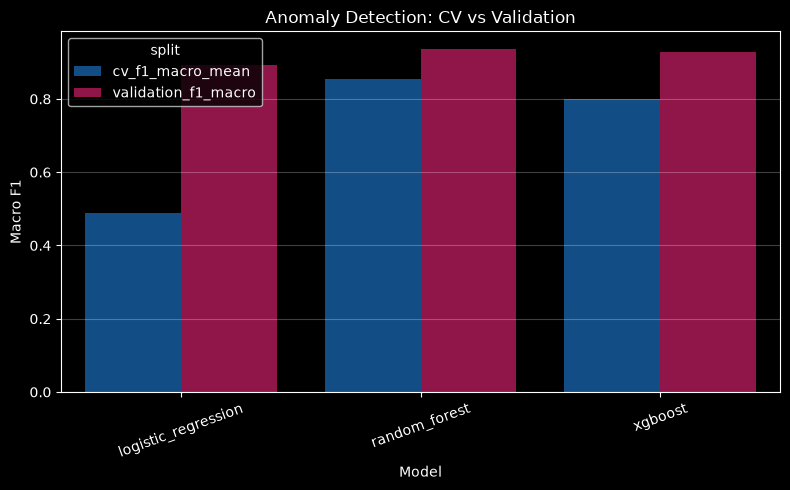

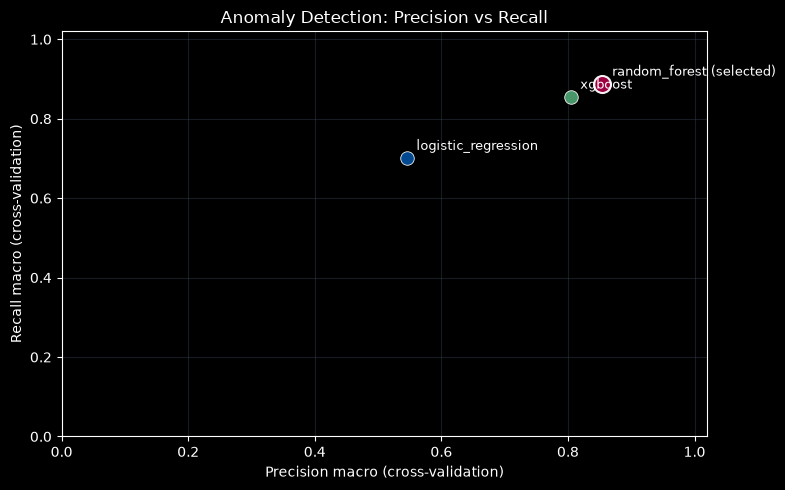

In [2]:
task_results = comparison[comparison["task_name"] == "binary_detection"].copy()
display(task_results.sort_values("validation_f1_macro", ascending=False))
plot_data = task_results.melt(
    id_vars="model_name",
    value_vars=["cv_f1_macro_mean", "validation_f1_macro"],
    var_name="split",
    value_name="macro_f1",
).dropna()
fig, ax = plt.subplots(figsize=tuple(graphics["figsize"]))
sns.barplot(data=plot_data, x="model_name", y="macro_f1", hue="split", ax=ax)
ax.set(title="Anomaly Detection: CV vs Validation", xlabel="Model", ylabel="Macro F1")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
display(task_results.loc[task_results["selected"], ["model_name", "test_f1_macro"]])
plot_precision_recall(task_results, "Anomaly Detection: Precision vs Recall")

<div style="background: linear-gradient(135deg, #050505 0%, #071426 55%, #18000C 100%); border: 1px solid #303030; border-radius: 16px; padding: 20px 24px;">

<h3 style="color: #004D98; font-family: Arial, sans-serif; font-size: 17px; letter-spacing: 1px; margin: 0;">
1.2 · ANOMALY TYPE CLASSIFICATION
</h3>

<div style="height: 2px; width: 90px; margin-top: 14px; background: linear-gradient(90deg, #004D98, #A50044); border-radius: 5px;"></div>

</div>

,task_name,model_name,estimator,parameters,cv_f1_macro_mean,cv_f1_macro_std,cv_precision_macro_mean,cv_recall_macro_mean,validation_f1_macro,validation_f1_micro,...,test_f1_macro,test_f1_micro,test_f1_weighted,decision_thresholds,selected,artifact_path,group_split,grouping_strategy,cross_validation_folds,group_count
6,anomaly_type,xgboost,xgboost,"{""learning_rate"": 0.05, ""max_depth"": 7, ""n_est...",0.468534,0.020100,0.516799,0.485995,0.459996,0.671141,...,0.594507,0.801653,0.789637,[],True,results\models\anomaly_type\xgboost\model_bund...,True,overlapping_time_intervals,3,84
4,anomaly_type,random_forest,random_forest,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.481359,0.026324,0.504105,0.495238,0.438472,0.684564,...,NaN,NaN,NaN,[],False,results\models\anomaly_type\random_forest\mode...,True,overlapping_time_intervals,3,84
3,anomaly_type,logistic_regression,logistic_regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.384926,0.072765,0.396319,0.444628,0.320782,0.503356,...,NaN,NaN,NaN,[],False,results\models\anomaly_type\logistic_regressio...,True,overlapping_time_intervals,3,84
5,anomaly_type,svm,svm,"{""C"": 0.5, ""class_weight"": ""balanced"", ""kernel...",0.330991,0.081395,0.401851,0.380912,0.192648,0.288591,...,NaN,NaN,NaN,[],False,results\models\anomaly_type\svm\model_bundle.j...,True,overlapping_time_intervals,3,84


,model_name,test_f1_macro
6,xgboost,0.594507


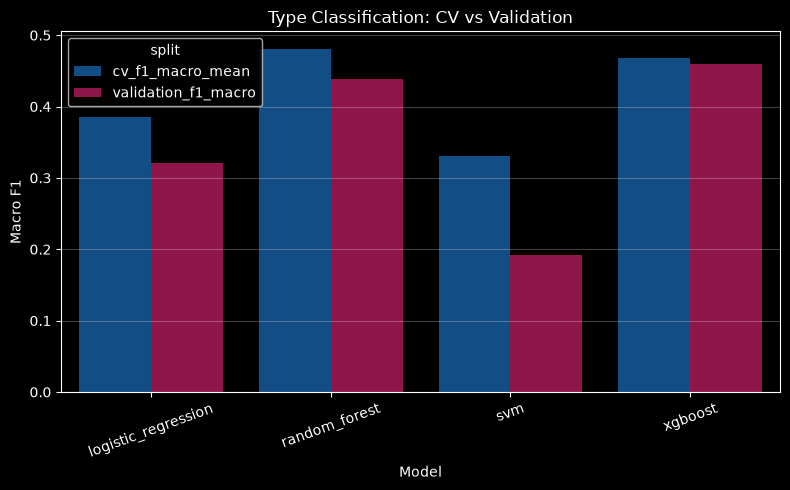

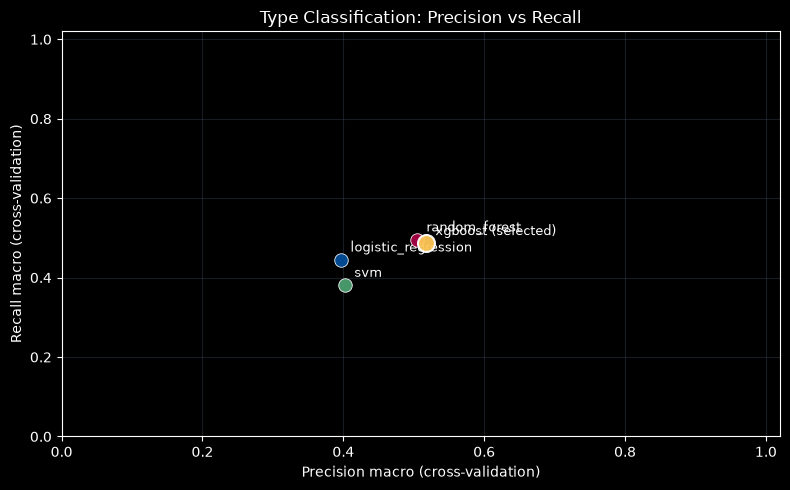

In [3]:
task_results = comparison[comparison["task_name"] == "anomaly_type"].copy()
display(task_results.sort_values("validation_f1_macro", ascending=False))
plot_data = task_results.melt(
    id_vars="model_name",
    value_vars=["cv_f1_macro_mean", "validation_f1_macro"],
    var_name="split",
    value_name="macro_f1",
).dropna()
fig, ax = plt.subplots(figsize=tuple(graphics["figsize"]))
sns.barplot(data=plot_data, x="model_name", y="macro_f1", hue="split", ax=ax)
ax.set(title="Type Classification: CV vs Validation", xlabel="Model", ylabel="Macro F1")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
display(task_results.loc[task_results["selected"], ["model_name", "test_f1_macro"]])
plot_precision_recall(task_results, "Type Classification: Precision vs Recall")

<div style="background: linear-gradient(135deg, #050505 0%, #071426 55%, #18000C 100%); border: 1px solid #303030; border-radius: 16px; padding: 20px 24px;">

<h3 style="color: #A50044; font-family: Arial, sans-serif; font-size: 17px; letter-spacing: 1px; margin: 0;">
1.3 · TEMPORAL ANOMALY LOCALIZATION
</h3>

<div style="height: 2px; width: 90px; margin-top: 14px; background: linear-gradient(90deg, #004D98, #A50044); border-radius: 5px;"></div>

</div>

,task_name,model_name,estimator,parameters,cv_f1_macro_mean,cv_f1_macro_std,cv_precision_macro_mean,cv_recall_macro_mean,validation_f1_macro,validation_f1_micro,...,test_f1_macro,test_f1_micro,test_f1_weighted,decision_thresholds,selected,artifact_path,group_split,grouping_strategy,cross_validation_folds,group_count
8,temporal_localization,random_forest,random_forest,"{""max_depth"": null, ""min_samples_leaf"": 2, ""n_...",0.768259,0.073905,0.766635,0.795049,0.932113,0.944736,...,0.825661,0.885912,0.875734,[0.15628571428571428],True,results\models\temporal_localization\random_fo...,True,overlapping_time_intervals,3,84
9,temporal_localization,xgboost,xgboost,"{""learning_rate"": 0.05, ""max_depth"": 4, ""n_est...",0.812488,0.037140,0.807458,0.819808,0.929705,0.941590,...,NaN,NaN,NaN,[0.306130975484848],False,results\models\temporal_localization\xgboost\m...,True,overlapping_time_intervals,3,84
7,temporal_localization,logistic_regression,logistic_regression,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.682463,0.045361,0.686961,0.724321,0.718104,0.784658,...,NaN,NaN,NaN,[0.21843887865543365],False,results\models\temporal_localization\logistic_...,True,overlapping_time_intervals,3,84


,model_name,test_f1_macro,decision_thresholds
8,random_forest,0.825661,[0.15628571428571428]


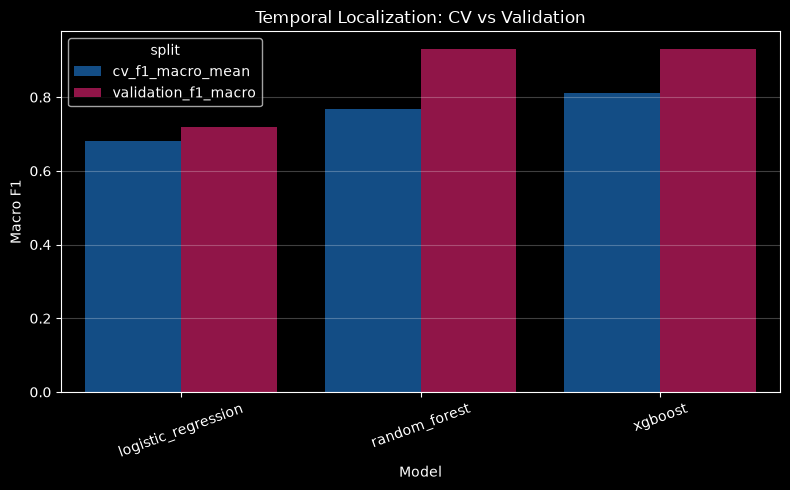

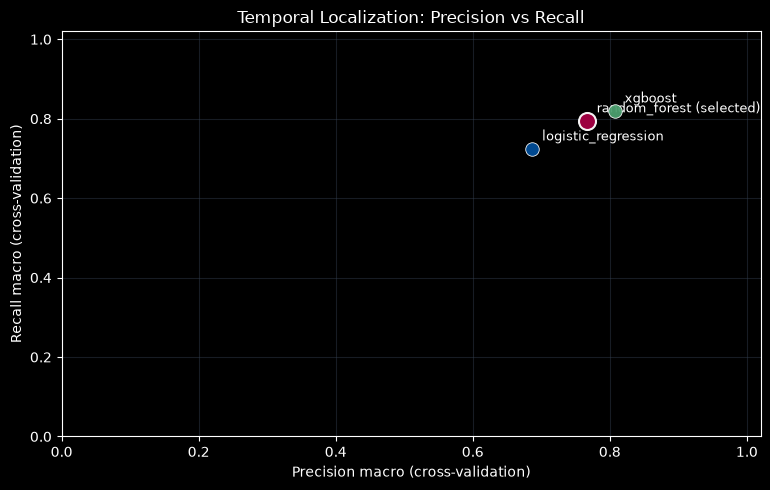

In [4]:
task_results = comparison[comparison["task_name"] == "temporal_localization"].copy()
display(task_results.sort_values("validation_f1_macro", ascending=False))
plot_data = task_results.melt(
    id_vars="model_name",
    value_vars=["cv_f1_macro_mean", "validation_f1_macro"],
    var_name="split",
    value_name="macro_f1",
).dropna()
fig, ax = plt.subplots(figsize=tuple(graphics["figsize"]))
sns.barplot(data=plot_data, x="model_name", y="macro_f1", hue="split", ax=ax)
ax.set(title="Temporal Localization: CV vs Validation", xlabel="Model", ylabel="Macro F1")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
display(task_results.loc[task_results["selected"], ["model_name", "test_f1_macro", "decision_thresholds"]])
plot_precision_recall(task_results, "Temporal Localization: Precision vs Recall")

<div style="background: linear-gradient(135deg, #050505 0%, #071426 55%, #18000C 100%); border: 1px solid #303030; border-radius: 16px; padding: 20px 24px;">

<h3 style="color: #004D98; font-family: Arial, sans-serif; font-size: 17px; letter-spacing: 1px; margin: 0;">
2.4 · AFFECTED KPI IDENTIFICATION
</h3>

<div style="height: 2px; width: 90px; margin-top: 14px; background: linear-gradient(90deg, #004D98, #A50044); border-radius: 5px;"></div>

</div>

,task_name,model_name,estimator,parameters,cv_f1_macro_mean,cv_f1_macro_std,cv_precision_macro_mean,cv_recall_macro_mean,validation_f1_macro,validation_f1_micro,...,test_f1_macro,test_f1_micro,test_f1_weighted,decision_thresholds,selected,artifact_path,group_split,grouping_strategy,cross_validation_folds,group_count
10,affected_kpis,one_vs_rest_logistic_regression,one_vs_rest_logistic_regression,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.769978,0.062304,0.763396,0.820007,0.922343,0.953336,...,0.877371,0.905093,0.908693,"[0.2291000485420227, 0.6857719421386719, 0.203...",True,results\models\affected_kpis\one_vs_rest_logis...,True,overlapping_time_intervals,5,84
12,affected_kpis,classifier_chain,classifier_chain,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.760162,0.075978,0.759767,0.829376,0.884623,0.931906,...,NaN,NaN,NaN,"[0.32285372095745246, 0.7400112471565882, 0.08...",False,results\models\affected_kpis\classifier_chain\...,True,overlapping_time_intervals,5,84
11,affected_kpis,random_forest,random_forest,"{""max_depth"": 12, ""min_samples_leaf"": 2, ""n_es...",0.618384,0.062254,0.672893,0.720551,0.867590,0.896580,...,NaN,NaN,NaN,"[0.4545883005883005, 0.7673531746031744, 0.236...",False,results\models\affected_kpis\random_forest\mod...,True,overlapping_time_intervals,5,84


,model_name,test_f1_macro,test_f1_micro
10,one_vs_rest_logistic_regression,0.877371,0.905093


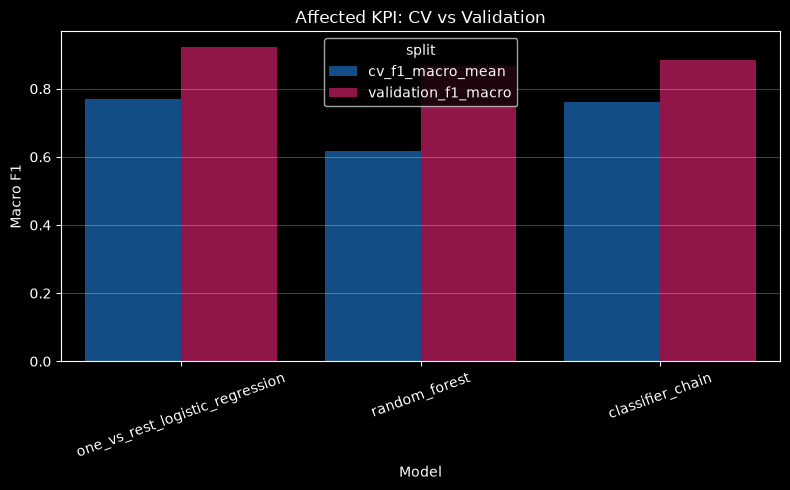

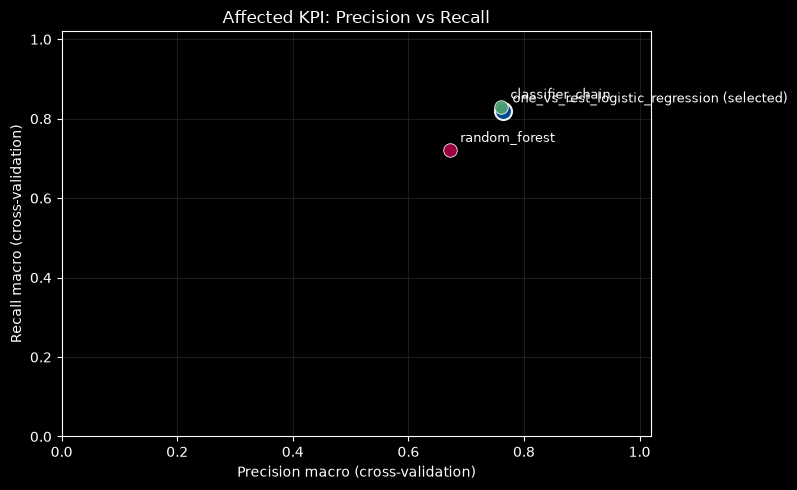

In [5]:
task_results = comparison[comparison["task_name"] == "affected_kpis"].copy()
display(task_results.sort_values("validation_f1_macro", ascending=False))
plot_data = task_results.melt(
    id_vars="model_name",
    value_vars=["cv_f1_macro_mean", "validation_f1_macro"],
    var_name="split",
    value_name="macro_f1",
).dropna()
fig, ax = plt.subplots(figsize=tuple(graphics["figsize"]))
sns.barplot(data=plot_data, x="model_name", y="macro_f1", hue="split", ax=ax)
ax.set(title="Affected KPI: CV vs Validation", xlabel="Model", ylabel="Macro F1")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
display(task_results.loc[task_results["selected"], ["model_name", "test_f1_macro", "test_f1_micro"]])
plot_precision_recall(task_results, "Affected KPI: Precision vs Recall")